# Researchly: classifying research abstracts (Questions 1 and 2)

The data are 1,138 abstracts labelled `ai` or `classical`. The notebook cleans the text, picks features, fits a baseline, trains four further models, tests one improvement, and saves the best pipeline for the web app.

In [1]:
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
warnings.filterwarnings("ignore")

sys.path.insert(0, "../deployment")          # shared cleaning code
from text_utils import preprocess, clean_text

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate, learning_curve
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import chi2
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

SEED = 42
FIG = "../outputs/figures/"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
results = {}      # collected for the written report

## 1.1 Load and denoise the data

In [2]:
raw = pd.read_json("../data/research_abstracts.json")
print(raw.shape)
print(raw.dtypes, "\n")
print(raw.isna().sum(), "\n")
print(raw["Label"].value_counts())
raw.head()

(1138, 3)
DOI         str
Abstract    str
Label       str
dtype: object 

DOI         4
Abstract    0
Label       0
dtype: int64 

Label
classical    900
ai           238
Name: count, dtype: int64


,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical


In [3]:
print("duplicated abstracts:", raw["Abstract"].duplicated().sum())
print("duplicated DOIs     :", raw["DOI"].dropna().duplicated().sum())
dup_rows = raw[raw["Abstract"].duplicated(keep=False)].sort_values("Abstract")
print("label conflicts among duplicates:", (dup_rows.groupby("Abstract")["Label"].nunique() > 1).sum())
df = raw.drop_duplicates(subset="Abstract").reset_index(drop=True)
print("rows kept:", len(df))
results["rows_raw"] = len(raw); results["rows_clean"] = len(df)
results["label_counts"] = df["Label"].value_counts().to_dict()

duplicated abstracts: 13
duplicated DOIs     : 0
label conflicts among duplicates: 0
rows kept: 1125


In [4]:
sample = df.loc[0, "Abstract"]
print("BEFORE:\n", sample[:350], "\n")
print("AFTER:\n", preprocess(sample)[:350])

BEFORE:
 Forward-looking forecasting of the inflation rate could help the central bank and other government departments to better use monetary policy to stabilize prices and prevent the impact of inflation on market entities, especially for low- and middle-income groups. It can also help financial institutions and investors better make investment decisions. 



AFTER:
 forward look forecast inflation rate help central bank government department good monetary policy stabilize price prevent impact inflation market entity especially low middle income group help financial institution investor good make investment decision sense forecast inflation rate great significance exist literature mainly linear model autoregres


empty after cleaning: 0
       words_raw  words_clean
count     1125.0       1125.0
mean       171.6         94.7
std        103.9         56.5
min         16.0          9.0
25%        116.0         65.0
50%        152.0         85.0
75%        201.0        110.0
max       2075.0       1157.0

longest raw record starts with: Francesca Gino, Erin L. Krupka, Roberto A. Weber Does the option for regulatory oversight change behavior? Although moni
starts with 'Summary': 5
contains a URL: 7


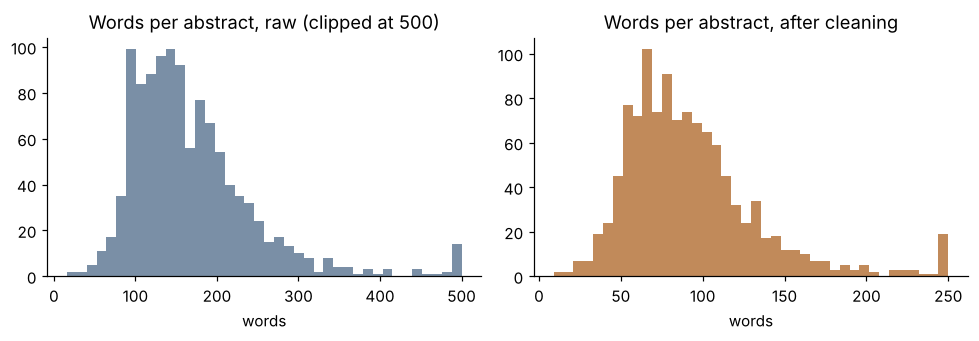

In [5]:
df["clean"] = df["Abstract"].map(preprocess)
df["words_raw"] = df["Abstract"].str.split().str.len()
df["words_clean"] = df["clean"].str.split().str.len()
print("empty after cleaning:", (df["words_clean"] == 0).sum())
print(df[["words_raw", "words_clean"]].describe().round(1))

# a few of the odd records the cleaner has to cope with
print("\nlongest raw record starts with:", df.loc[df.words_raw.idxmax(), "Abstract"][:120])
print("starts with 'Summary':", df["Abstract"].str.startswith("Summary").sum())
print("contains a URL:", df["Abstract"].str.contains("http|www\\.").sum())

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].hist(df["words_raw"].clip(upper=500), bins=40, color="#7a8fa6")
ax[0].set_title("Words per abstract, raw (clipped at 500)"); ax[0].set_xlabel("words")
ax[1].hist(df["words_clean"].clip(upper=250), bins=40, color="#c18a5a")
ax[1].set_title("Words per abstract, after cleaning"); ax[1].set_xlabel("words")
plt.tight_layout(); plt.savefig(FIG + "q1_length_before_after.png", dpi=150); plt.show()
results["median_words_raw"] = float(df.words_raw.median()); results["median_words_clean"] = float(df.words_clean.median())

The raw file has 1,138 rows and three columns. Four DOIs are missing. Thirteen abstracts appear twice under different DOIs, always with the same label, so the repeats were dropped and 1,125 records remain (890 classical, 235 AI).

Cleaning removes HTML tags, URLs, emails, DOI strings, bracketed references, digits and punctuation, then lowercases, drops stop words and lemmatises. The median abstract shrinks from 152 to 85 words. A handful of records carry junk the cleaner only partly handles, for example one entry that begins with a list of author names and one that runs to over 2,000 words. They were kept, since removing them by hand would not scale to new input.

## 1.2 Choose features

In [6]:
df["y"] = (df["Label"] == "ai").astype(int)
cols = pd.DataFrame({
    "column": ["DOI", "Abstract", "Label"],
    "type": ["identifier", "free text", "class label"],
    "missing": [raw["DOI"].isna().sum(), 0, 0],
    "distinct": [raw["DOI"].nunique(), raw["Abstract"].nunique(), raw["Label"].nunique()],
})
print(cols.to_string(index=False))

# Does the DOI carry any signal? Look at the registrant prefix (the part before the slash).
df["prefix"] = df["DOI"].fillna("missing").str.extract(r"^(10\.\d+|https?|missing)")[0]
pref = df.groupby("prefix")["y"].agg(["count", "mean"]).sort_values("count", ascending=False).head(8)
pref["mean"] = pref["mean"].round(2)
print("\nShare of AI abstracts by DOI prefix (top 8 prefixes):")
print(pref)

  column        type  missing  distinct
     DOI  identifier        4      1134
Abstract   free text        0      1125
   Label class label        0         2

Share of AI abstracts by DOI prefix (top 8 prefixes):
          count  mean
prefix               
10.2139     292  0.11
10.1016     197  0.15
10.1007      71  0.31
10.1080      56  0.04
10.1109      53  0.83
10.1111      53  0.06
10.1002      33  0.06
10.48550     29  0.76


In [7]:
print("Mean words per abstract by class:")
print(df.groupby("Label")["words_raw"].mean().round(1))
print("\ncorrelation of word count with the AI label:", round(df["words_raw"].corr(df["y"]), 3))

Mean words per abstract by class:
Label
ai           181.1
classical    169.1
Name: words_raw, dtype: float64

correlation of word count with the AI label: 0.047


      term  chi2  ai_docs_%  classical_docs_%
   machine 397.7       29.8               0.0
     learn 380.6       39.1               2.5
   network 376.1       28.1               0.8
    neural 350.3       25.5               0.1
 algorithm 290.9       20.0               0.4
    method 278.0       39.1              13.5
regression 189.4       29.4               9.7
      gold 183.0        6.4               1.0
       ann 169.3        6.8               0.1
      lstm 166.6        9.4               0.0
       svr 151.5        5.1               0.0
    forest 143.9        8.5               0.0
artificial 135.4       10.2               0.2
  quantile 119.4        4.7               0.1
   bitcoin 113.6        3.0               0.0
 sentiment 106.6        6.0               0.2
     train 106.4       10.6               0.6
      tree 102.3        6.0               0.0
      data 100.3       55.7              39.7
   predict  94.9       45.5              22.1

vocabulary (min_df=5): 2072 terms

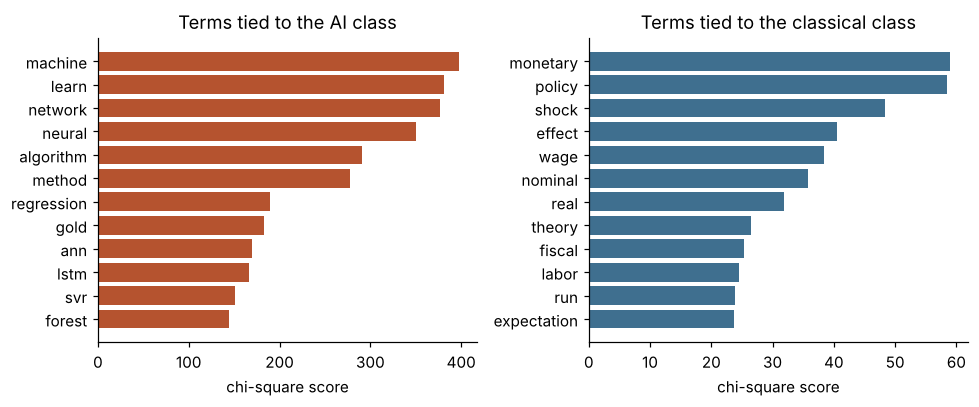

In [8]:
# Rank terms with chi-square on a bag-of-words matrix built from the cleaned text.
cv_all = CountVectorizer(min_df=5)
Xall = cv_all.fit_transform(df["clean"])
scores, pvals = chi2(Xall, df["y"])
terms = np.array(cv_all.get_feature_names_out())

# direction of each term: which class uses it more often (relative document frequency)
pos_rate = np.asarray((Xall[df["y"].values == 1] > 0).mean(axis=0)).ravel()
neg_rate = np.asarray((Xall[df["y"].values == 0] > 0).mean(axis=0)).ravel()
top = np.argsort(scores)[::-1][:30]
chi_tab = pd.DataFrame({"term": terms[top], "chi2": scores[top].round(1),
                        "ai_docs_%": (pos_rate[top]*100).round(1), "classical_docs_%": (neg_rate[top]*100).round(1)})
print(chi_tab.head(20).to_string(index=False))
print("\nvocabulary (min_df=5):", len(terms), "terms")
results["chi2_top"] = chi_tab.head(15).to_dict("records")

order_all = np.argsort(scores)[::-1]
top_ai = [i for i in order_all if pos_rate[i] > neg_rate[i]][:12]
top_cl = [i for i in order_all if pos_rate[i] <= neg_rate[i]][:12]
results["chi2_classical"] = list(terms[top_cl])
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
ax[0].barh(terms[top_ai][::-1], scores[top_ai][::-1], color="#b5532f"); ax[0].set_title("Terms tied to the AI class")
ax[1].barh(terms[top_cl][::-1], scores[top_cl][::-1], color="#3f6f8f"); ax[1].set_title("Terms tied to the classical class")
for a in ax: a.set_xlabel("chi-square score")
plt.tight_layout(); plt.savefig(FIG + "q1_chi2_terms.png", dpi=150); plt.show()

`Abstract` is the only column that describes content, so it supplies the features. `Label` is the target. `DOI` is an identifier and is left out. It does correlate with the label (83% of IEEE DOIs and 76% of arXiv DOIs are AI), but that reflects where a paper was published, not what it says. A classifier built on it would fail on any abstract without a DOI, including text typed into the web app. Abstract length is almost unrelated to the label (correlation 0.05), so no length feature was added.

The text is turned into features with bag-of-words and TF-IDF counts, and chi-square scores rank the terms. The top AI terms are what one would expect (*machine*, *learn*, *network*, *neural*, *algorithm*, *lstm*, *forest*). A few dataset quirks also appear, such as *gold* and *bitcoin*, which come from many price-forecasting papers in the AI group. The classical class leans on *monetary*, *policy*, *shock*, *wage* and *nominal*.

## 1.3 Baseline model

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["y"], test_size=0.2, stratify=df["y"], random_state=SEED)
print("train:", X_train.shape[0], " test:", X_test.shape[0])
print("AI share  train: %.3f   test: %.3f" % (y_train.mean(), y_test.mean()))
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results["n_train"] = int(len(X_train)); results["n_test"] = int(len(X_test))
results["n_test_ai"] = int(y_test.sum())

train: 900  test: 225
AI share  train: 0.209   test: 0.209


In [10]:
# Two feature sets were compared on the training data only. Cross-validated F1 for the AI class,
# same classifier (Multinomial NB) in both cases.
for name, vec in [("bag of words", CountVectorizer()),
                  ("tf-idf", TfidfVectorizer()),
                  ("bag of words, 1-2 grams, min_df=2", CountVectorizer(ngram_range=(1, 2), min_df=2))]:
    s = cross_val_score(make_pipeline(vec, MultinomialNB()), X_train, y_train, cv=cv5, scoring="f1")
    print(f"{name:38s} F1 = {s.mean():.3f} (+/- {s.std():.3f})")

bag of words                           F1 = 0.767 (+/- 0.040)


tf-idf                                 F1 = 0.050 (+/- 0.053)


bag of words, 1-2 grams, min_df=2      F1 = 0.778 (+/- 0.052)


Plain word counts work well with Naive Bayes (F1 0.767 in cross-validation). Adding bigrams with `min_df=2` gives 0.778, a gain that is smaller than the fold-to-fold spread. TF-IDF weights collapse to an F1 of 0.05 because the tiny values leave Naive Bayes dominated by the class prior. The baseline therefore uses plain counts and unigrams.

In [11]:
def scores(model, X, y):
    p = model.predict(X)
    return {"accuracy": accuracy_score(y, p), "precision": precision_score(y, p, zero_division=0),
            "recall": recall_score(y, p), "f1": f1_score(y, p), "macro_f1": f1_score(y, p, average="macro")}

def show_cm(model, X, y, title, fname=None):
    fig, ax = plt.subplots(figsize=(3.6, 3.2))
    ConfusionMatrixDisplay.from_estimator(model, X, y, display_labels=["classical", "ai"],
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(title, fontsize=10); plt.tight_layout()
    if fname: plt.savefig(FIG + fname, dpi=150)
    plt.show()

majority-class accuracy on test: 0.791 (F1 for AI = 0)


           train   test
accuracy   0.964  0.871
precision  0.902  0.688
recall     0.931  0.702
f1         0.916  0.695
macro_f1   0.947  0.807

5-fold CV on training data: accuracy 0.904, F1 0.767 (+/- 0.040)

               precision    recall  f1-score   support

   classical      0.921     0.916     0.918       178
          ai      0.688     0.702     0.695        47

    accuracy                          0.871       225
   macro avg      0.804     0.809     0.807       225
weighted avg      0.872     0.871     0.872       225



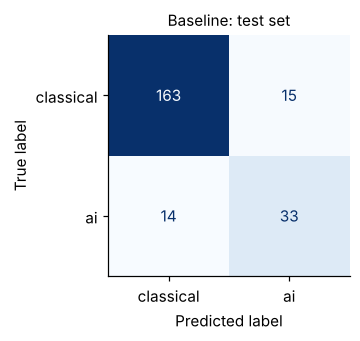

In [12]:
# Reference point: always predict the majority class.
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("majority-class accuracy on test: %.3f (F1 for AI = 0)" % accuracy_score(y_test, dummy.predict(X_test)))

baseline = make_pipeline(CountVectorizer(), MultinomialNB())
baseline.fit(X_train, y_train)

tr, te = scores(baseline, X_train, y_train), scores(baseline, X_test, y_test)
cvres = cross_validate(baseline, X_train, y_train, cv=cv5, scoring=["accuracy", "f1"])
perf = pd.DataFrame({"train": tr, "test": te}).round(3)
print(perf)
print("\n5-fold CV on training data: accuracy %.3f, F1 %.3f (+/- %.3f)" % (
    cvres["test_accuracy"].mean(), cvres["test_f1"].mean(), cvres["test_f1"].std()))
print("\n", classification_report(y_test, baseline.predict(X_test), target_names=["classical", "ai"], digits=3))
results["baseline"] = {"train": tr, "test": te, "cv_f1": float(cvres["test_f1"].mean()),
                       "cv_f1_std": float(cvres["test_f1"].std()), "cv_acc": float(cvres["test_accuracy"].mean())}
show_cm(baseline, X_test, y_test, "Baseline: test set", "q1_baseline_cm.png")

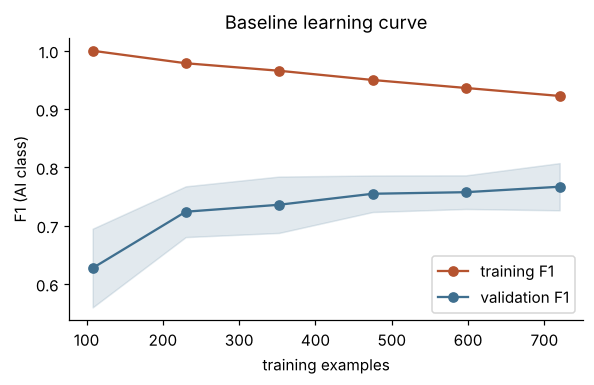

In [13]:
sizes, tr_sc, va_sc = learning_curve(baseline, X_train, y_train, cv=cv5, scoring="f1",
                                     train_sizes=np.linspace(0.15, 1.0, 6), random_state=SEED)
plt.figure(figsize=(5.5, 3.6))
plt.plot(sizes, tr_sc.mean(1), "o-", color="#b5532f", label="training F1")
plt.plot(sizes, va_sc.mean(1), "o-", color="#3f6f8f", label="validation F1")
plt.fill_between(sizes, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), color="#3f6f8f", alpha=.15)
plt.xlabel("training examples"); plt.ylabel("F1 (AI class)"); plt.title("Baseline learning curve")
plt.legend(); plt.tight_layout(); plt.savefig(FIG + "q1_baseline_learning_curve.png", dpi=150); plt.show()

**Reading the numbers.** A model that always says "classical" scores 79.1% accuracy on the test set, so accuracy alone says little here and F1 on the AI class is the figure to watch. The baseline reaches 0.695 on the test set (precision 0.688, recall 0.702) and 0.767 in cross-validation, with accuracy of 87.1%.

**Learning and generalisation.** Training F1 is 0.916 against 0.695 on the test set, a gap of about 0.22. The learning curve shows the same thing. Training F1 falls as data are added while validation F1 rises slowly and flattens near 0.77, with the two curves still far apart. The model memorises part of the training vocabulary and is overfitting. More labelled data would help a little, but the flat validation curve points to a limit set by the features and the model, so a model that treats the rare class differently is worth trying.

## 2.1 Four more models

In [14]:
tfidf = lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
tfidf_small = lambda: TfidfVectorizer(min_df=3, max_features=3000)

def make_models(balanced=False):
    cw = "balanced" if balanced else None
    return {
        "Logistic Regression": make_pipeline(tfidf(), LogisticRegression(max_iter=2000, class_weight=cw)),
        "Linear SVM": make_pipeline(tfidf(), LinearSVC(class_weight=cw)),
        "Random Forest": make_pipeline(TfidfVectorizer(min_df=2),
                                       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1,
                                                              class_weight="balanced_subsample" if balanced else None)),
        "Gradient Boosting": make_pipeline(tfidf_small(), GradientBoostingClassifier(random_state=SEED)),
    }

def fit_eval(name, model, balanced=False):
    """Fit on the training split, return CV and hold-out numbers."""
    fit_kw = {}
    if balanced and name == "Gradient Boosting":     # no class_weight argument, use sample weights
        fit_kw = {"gradientboostingclassifier__sample_weight": compute_sample_weight("balanced", y_train)}
    cv_f1 = []
    for tr_i, va_i in cv5.split(X_train, y_train):
        m = make_models(balanced)[name]
        kw = {}
        if balanced and name == "Gradient Boosting":
            kw = {"gradientboostingclassifier__sample_weight": compute_sample_weight("balanced", y_train.iloc[tr_i])}
        m.fit(X_train.iloc[tr_i], y_train.iloc[tr_i], **kw)
        cv_f1.append(f1_score(y_train.iloc[va_i], m.predict(X_train.iloc[va_i])))
    model.fit(X_train, y_train, **fit_kw)
    out = {"cv_f1": np.mean(cv_f1), "train_f1": f1_score(y_train, model.predict(X_train))}
    out.update({"test_" + k: v for k, v in scores(model, X_test, y_test).items()})
    return out

rows = {"Baseline (NB + counts)": {"cv_f1": results["baseline"]["cv_f1"], "train_f1": tr["f1"],
                                    **{"test_" + k: v for k, v in te.items()}}}
fitted_plain = make_models(False)
for name, m in fitted_plain.items():
    rows[name] = fit_eval(name, m, balanced=False)
table21 = pd.DataFrame(rows).T[["cv_f1", "train_f1", "test_f1", "test_accuracy", "test_precision", "test_recall"]].round(3)
print(table21)
results["table21"] = table21.reset_index().rename(columns={"index": "model"}).to_dict("records")

                        cv_f1  train_f1  test_f1  test_accuracy  \
Baseline (NB + counts)  0.767     0.916    0.695          0.871   
Logistic Regression     0.428     0.633    0.379          0.840   
Linear SVM              0.789     1.000    0.725          0.902   
Random Forest           0.698     1.000    0.676          0.898   
Gradient Boosting       0.765     0.953    0.675          0.884   

                        test_precision  test_recall  
Baseline (NB + counts)           0.688        0.702  
Logistic Regression              1.000        0.234  
Linear SVM                       0.879        0.617  
Random Forest                    1.000        0.511  
Gradient Boosting                0.818        0.574  


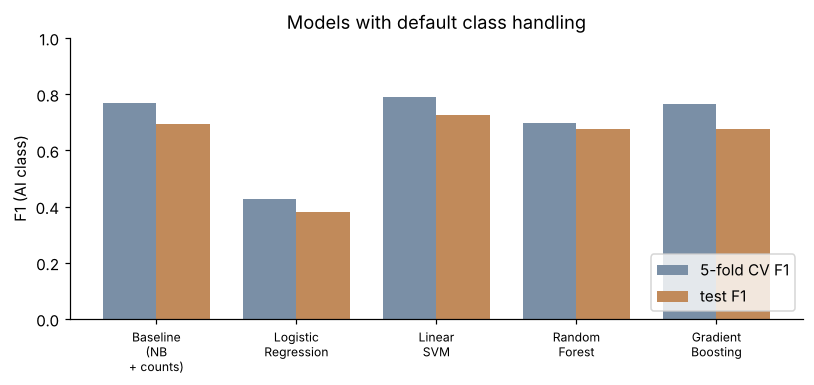

In [15]:
t = table21.copy()
x = np.arange(len(t)); w = 0.38
plt.figure(figsize=(7.5, 3.6))
plt.bar(x - w/2, t["cv_f1"], w, label="5-fold CV F1", color="#7a8fa6")
plt.bar(x + w/2, t["test_f1"], w, label="test F1", color="#c18a5a")
plt.xticks(x, [i.replace(" (NB + counts)", "\n(NB + counts)").replace(" ", "\n", 1) for i in t.index], fontsize=8)
plt.ylabel("F1 (AI class)"); plt.ylim(0, 1); plt.legend(loc="lower right"); plt.title("Models with default class handling")
plt.tight_layout(); plt.savefig(FIG + "q2_models_default.png", dpi=150); plt.show()

Logistic Regression, Linear SVM and Random Forest use TF-IDF features (the forest uses unigrams only); Gradient Boosting uses TF-IDF capped at 3,000 terms to keep training time down. All start with default class handling.

Only the Linear SVM beats the baseline on both measures (CV F1 0.789 against 0.767, test F1 0.725 against 0.695). Logistic Regression does worse than the baseline, and its test precision of 1.00 with recall of 0.23 shows why. Under the 79/21 class split it almost never predicts AI. Random Forest has the same problem to a lesser degree, with precision 1.00 and recall 0.51. Gradient Boosting sits close to the baseline.

## 2.2 Enhancement: class weighting

In [16]:
# Enhancement: cost-sensitive learning. Each class is weighted by the inverse of its frequency, so one AI
# abstract counts about four times as much as one classical abstract during training.
print("class weights used:", dict(zip(["classical", "ai"],
      (len(y_train) / (2 * np.bincount(y_train))).round(2))))

rows_b = {}
fitted_bal = make_models(True)
for name, m in fitted_bal.items():
    rows_b[name] = fit_eval(name, m, balanced=True)
table22 = pd.DataFrame(rows_b).T[["cv_f1", "train_f1", "test_f1", "test_accuracy", "test_precision", "test_recall"]].round(3)
print(table22)

cmp = pd.DataFrame({
    "CV F1 before": table21.loc[table22.index, "cv_f1"], "CV F1 after": table22["cv_f1"],
    "test F1 before": table21.loc[table22.index, "test_f1"], "test F1 after": table22["test_f1"],
    "test recall before": table21.loc[table22.index, "test_recall"], "test recall after": table22["test_recall"]})
print("\n", cmp.round(3))
results["table22"] = table22.reset_index().rename(columns={"index": "model"}).to_dict("records")
results["cmp22"] = cmp.round(3).reset_index().rename(columns={"index": "model"}).to_dict("records")

class weights used: {'classical': np.float64(0.63), 'ai': np.float64(2.39)}


                     cv_f1  train_f1  test_f1  test_accuracy  test_precision  \
Logistic Regression  0.781     0.974    0.735          0.884           0.706   
Linear SVM           0.808     0.997    0.736          0.898           0.800   
Random Forest        0.657     1.000    0.648          0.889           0.958   
Gradient Boosting    0.748     1.000    0.753          0.898           0.761   

                     test_recall  
Logistic Regression        0.766  
Linear SVM                 0.681  
Random Forest              0.489  
Gradient Boosting          0.745  

                      CV F1 before  CV F1 after  test F1 before  test F1 after  \
Logistic Regression         0.428        0.781           0.379          0.735   
Linear SVM                  0.789        0.808           0.725          0.736   
Random Forest               0.698        0.657           0.676          0.648   
Gradient Boosting           0.765        0.748           0.675          0.753   

                

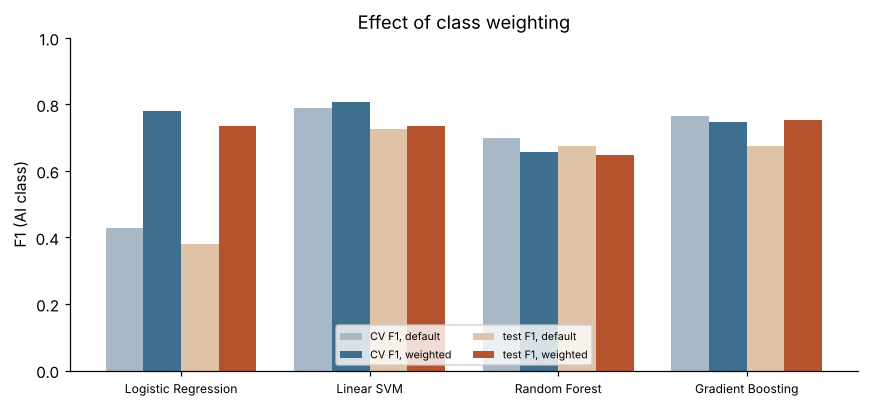

In [17]:
x = np.arange(len(cmp)); w = 0.2
plt.figure(figsize=(8, 3.8))
plt.bar(x - 1.5*w, cmp["CV F1 before"], w, label="CV F1, default", color="#a9b8c6")
plt.bar(x - 0.5*w, cmp["CV F1 after"], w, label="CV F1, weighted", color="#3f6f8f")
plt.bar(x + 0.5*w, cmp["test F1 before"], w, label="test F1, default", color="#e0c3a6")
plt.bar(x + 1.5*w, cmp["test F1 after"], w, label="test F1, weighted", color="#b5532f")
plt.xticks(x, cmp.index, fontsize=8); plt.ylim(0, 1); plt.ylabel("F1 (AI class)")
plt.legend(fontsize=7, ncol=2, loc="lower center"); plt.title("Effect of class weighting")
plt.tight_layout(); plt.savefig(FIG + "q2_class_weight_effect.png", dpi=150); plt.show()

Every default model errs toward the majority class. Class weighting addresses this directly by making each AI abstract count about 2.4 times as much as a classical one during training (900 training records, 21% AI). Random Forest uses `balanced_subsample` and Gradient Boosting receives sample weights.

The effect differs by model. Logistic Regression improves most, from CV F1 0.428 to 0.781 and test recall from 0.23 to 0.77. Linear SVM gains a little (CV 0.789 to 0.808, test recall 0.62 to 0.68). Gradient Boosting rises on the test set (0.675 to 0.753) but dips slightly in cross-validation. Random Forest does not benefit, since its trees already reach purity on the training data. The gains on the test set are partly noise, because it holds only 47 AI abstracts.

selected: Linear SVM | CV F1 = 0.808

              precision    recall  f1-score   support

   classical      0.919     0.955     0.937       178
          ai      0.800     0.681     0.736        47

    accuracy                          0.898       225
   macro avg      0.859     0.818     0.836       225
weighted avg      0.894     0.898     0.895       225



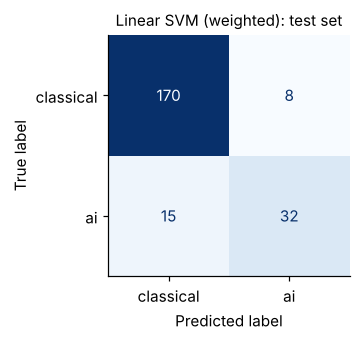

In [18]:
best_name = table22["cv_f1"].idxmax()          # chosen on cross-validation, not on the test set
best_model = fitted_bal[best_name]
print("selected:", best_name, "| CV F1 = %.3f" % table22.loc[best_name, "cv_f1"])
print()
print(classification_report(y_test, best_model.predict(X_test), target_names=["classical", "ai"], digits=3))
show_cm(best_model, X_test, y_test, best_name + " (weighted): test set", "q2_best_cm.png")
results["best_name"] = best_name
results["best_test"] = scores(best_model, X_test, y_test)
results["best_train"] = scores(best_model, X_train, y_train)

In [19]:
# The hold-out set has only 47 AI abstracts, so one split is noisy. Repeat 5-fold CV three times on all
# records (15 folds) and compare the baseline with the selected model fold by fold.
from sklearn.model_selection import RepeatedStratifiedKFold
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
f_base = cross_val_score(make_pipeline(CountVectorizer(), MultinomialNB()), df["clean"], df["y"], cv=rcv, scoring="f1")
f_best = cross_val_score(make_models(True)[best_name], df["clean"], df["y"], cv=rcv, scoring="f1")
print("baseline      F1 = %.3f (+/- %.3f)" % (f_base.mean(), f_base.std()))
print("%-13s F1 = %.3f (+/- %.3f)" % (best_name, f_best.mean(), f_best.std()))
print("selected model wins in %d of 15 folds; mean paired gain %.3f" % ((f_best > f_base).sum(), (f_best - f_base).mean()))
results["repeated"] = {"base_mean": float(f_base.mean()), "base_std": float(f_base.std()),
                       "best_mean": float(f_best.mean()), "best_std": float(f_best.std()),
                       "wins": int((f_best > f_base).sum()), "gain": float((f_best - f_base).mean())}

baseline      F1 = 0.745 (+/- 0.034)
Linear SVM    F1 = 0.780 (+/- 0.031)
selected model wins in 12 of 15 folds; mean paired gain 0.035


In [20]:
# Which terms push the selected model toward each class?
vec, clf = best_model.steps[0][1], best_model.steps[-1][1]
if hasattr(clf, "coef_"):
    coef = clf.coef_.ravel(); names = np.array(vec.get_feature_names_out())
    order = np.argsort(coef)
    print("towards classical:", ", ".join(names[order[:15]]))
    print("towards AI       :", ", ".join(names[order[::-1][:15]]))
    results["top_ai_terms"] = list(names[order[::-1][:15]]); results["top_classical_terms"] = list(names[order[:15]])

towards classical: uncertainty, policy, horizon, cost, real, nominal, suggest, current, city, consumption, growth, post, hypothesis, estimate, expect
towards AI       : network, learn, neural network, neural, algorithm, quantile, sentiment, machine, machine learn, lstm, nonparametric, cluster, ann, review, method


In [21]:
pred = best_model.predict(X_test)
wrong = X_test.index[pred != y_test]
print("misclassified:", len(wrong), "of", len(y_test))
for i in wrong[:4]:
    print("\ntrue:", df.loc[i, "Label"], "| predicted:", "ai" if pred[list(X_test.index).index(i)] else "classical")
    print(df.loc[i, "Abstract"][:300], "...")

misclassified: 23 of 225

true: ai | predicted: classical
Share of government expenditures in the GDPs are increasing virtually everywhere. Available data for developed countries indicate that the beginnings of this upward trend date back to the mid-19th century. Interestingly, economic growth rates did not increase significantly over time despite the incr ...

true: ai | predicted: classical
Abstract                   How do individuals form expectations about future inflation? We propose that individuals overweight inflation experienced during their lifetimes. This approach modifies existing adaptive learning models to allow for age-dependent updating of expectations in response to inf ...

true: ai | predicted: classical
The fact that predictions of inflation can create a self-fulfilling expectations trap creates a powerful incentive to balance output and inflation. Media reports, as a source of public information, contribute to formation of inflation expectations. We investigate ho

The Linear SVM with class weights is selected, because it has the highest cross-validated F1 (0.808). The choice was made on the training folds, not on the test set.

On the 225 held-out abstracts it reaches F1 0.736, precision 0.800, recall 0.681 and accuracy 89.8%, against 0.695, 0.688, 0.702 and 87.1% for the baseline. Precision rises by 11 points and recall falls by 2. Over three repeats of 5-fold cross-validation on all records, it scores 0.780 against 0.745 for the baseline and wins in 12 of 15 folds. The improvement is real but small, roughly 3.5 F1 points.

The top terms for the AI class are *network*, *learn*, *neural network*, *algorithm*, *quantile*, *sentiment*, *machine learn* and *lstm*. Several of the misclassified AI abstracts are about expectations or government spending and never mention a learning method. They look like noisy labels, which probably caps what any model can reach on this data. Training F1 is near 1.0, so the model still overfits, as expected for a linear model on thousands of sparse features.

## 2.3 Save the model for deployment

In [22]:
# Final deployable pipeline. It takes the raw abstract text, so the cleaning step is part of the model.
# It is refitted on all labelled records before saving; the test figures above come from the train-only fit.
raw_X, all_y = df["Abstract"], df["y"]
final_vec = TfidfVectorizer(preprocessor=preprocess, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
final_clf = {"Linear SVM": LinearSVC(class_weight="balanced"),
             "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced")}.get(best_name)
if final_clf is None:
    raise SystemExit("selected model is not a TF-IDF linear model; adjust this cell")
final_pipe = Pipeline([("tfidf", final_vec), ("clf", final_clf)])

# sanity check: same recipe on raw text, train split only, should reproduce the test F1 above
Xr_tr, Xr_te = raw_X.loc[X_train.index], raw_X.loc[X_test.index]
check = Pipeline([("tfidf", TfidfVectorizer(preprocessor=preprocess, ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                  ("clf", type(final_clf)(**final_clf.get_params()))]).fit(Xr_tr, y_train)
print("raw-text pipeline test F1: %.3f (notebook model: %.3f)" % (f1_score(y_test, check.predict(Xr_te)), results["best_test"]["f1"]))

final_pipe.fit(raw_X, all_y)
joblib.dump({"pipeline": final_pipe, "labels": {0: "classical research", 1: "artificial intelligence"}},
            "../deployment/model.joblib")
print("saved ../deployment/model.joblib")

demo = ("Artificial intelligence (AI) has become a transformative technology in healthcare by enabling more accurate "
        "diagnosis, predictive analytics, and personalised treatment planning. Machine learning algorithms can analyse "
        "large volumes of medical data to identify patterns that assist clinicians in detecting diseases at earlier stages.")
print("demo prediction:", final_pipe.predict([demo])[0])

raw-text pipeline test F1: 0.736 (notebook model: 0.736)


saved ../deployment/model.joblib
demo prediction: 1


The saved object holds the full pipeline, so the cleaning step travels with it and the app can pass raw text straight in. A check on the train/test split reproduces the notebook's test F1 of 0.736. The pipeline saved for the app was then refitted on all 1,125 records. The Streamlit app in `deployment/` loads this file.

In [23]:
with open("../outputs/q1_q2_results.json", "w") as f:
    json.dump(results, f, indent=2, default=float)